<a href="https://colab.research.google.com/github/yesimkaya100619/YMG3/blob/main/odev1/notebooks/01_hog_svm_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os

# 1. Kaggle Token'ını Ortam Değişkeni Olarak Tanımla
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_960a3a6534b40dd3526c9798ec0f0385'

# 2. Veri Setini Doğrudan Colab'e İndir
!kaggle datasets download -d rhammell/ships-in-satellite-imagery

# 3. Zip Dosyasını Aç ve Temizle
!unzip -q ships-in-satellite-imagery.zip -d ./data
!rm ships-in-satellite-imagery.zip

print("Tebrikler! Veri seti başarıyla Colab ortamına indirildi ve çıkarıldı.")

Dataset URL: https://www.kaggle.com/datasets/rhammell/ships-in-satellite-imagery
License(s): CC-BY-SA-4.0
100% 185M/185M [00:01<00:00, 113MB/s]

Tebrikler! Veri seti başarıyla Colab ortamına indirildi ve çıkarıldı.


Toplam Görüntü Sayısı: 4000
Gemi Olan Sayısı (Etiket 1): 1000
Gemi Olmayan Sayı (Etiket 0): 3000


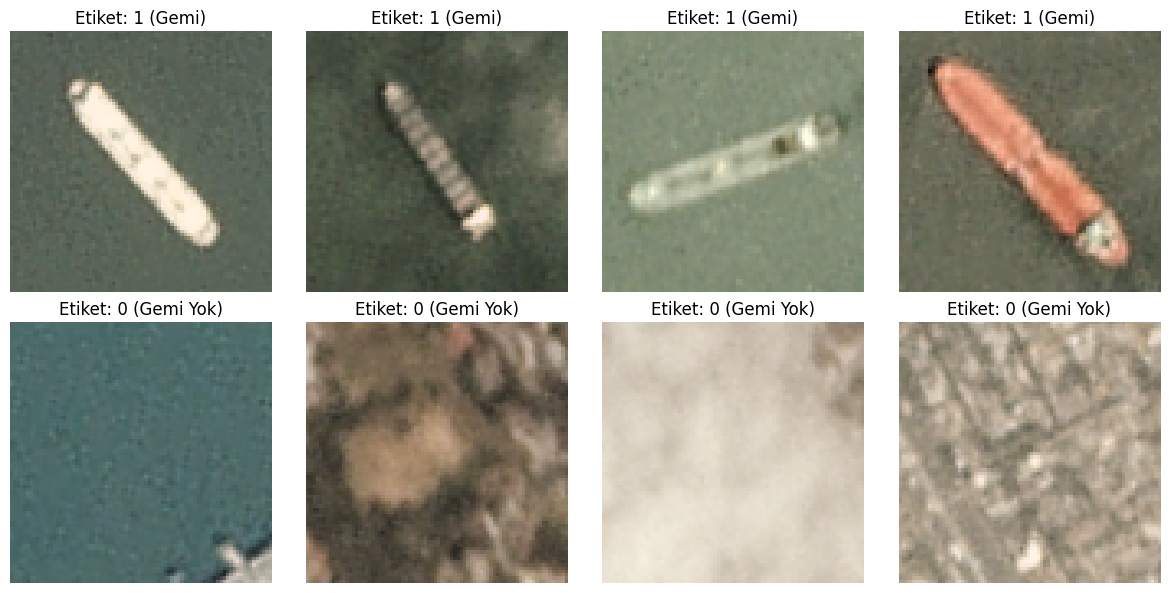

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt

# 1. JSON Verisini Yükle
with open('./data/shipsnet.json') as f:
    dataset = json.load(f)

# 2. Veriyi NumPy Dizilerine Dönüştür
data = np.array(dataset['data']).astype('uint8')
labels = np.array(dataset['labels'])

# 3. Görsel Boyutlandırma (80x80 piksel, 3 Kanal: RGB)
# [Örnek Sayısı, Kanal, Yükseklik, Genişlik] -> [Örnek Sayısı, Yükseklik, Genişlik, Kanal]
data = data.reshape(-1, 3, 80, 80).transpose(0, 2, 3, 1)

print(f"Toplam Görüntü Sayısı: {data.shape[0]}")
print(f"Gemi Olan Sayısı (Etiket 1): {np.sum(labels == 1)}")
print(f"Gemi Olmayan Sayı (Etiket 0): {np.sum(labels == 0)}")

# 4. Örnek Görselleri Çizdir
plt.figure(figsize=(12, 6))
for i in range(8):
    # İlk 4 tanesi Gemi (1), Son 4 tanesi Gemi Yok (0)
    idx = np.where(labels == 1)[0][i] if i < 4 else np.where(labels == 0)[0][i-4]

    plt.subplot(2, 4, i + 1)
    plt.imshow(data[idx])
    plt.title(f"Etiket: {labels[idx]} ({'Gemi' if labels[idx] == 1 else 'Gemi Yok'})")
    plt.axis('off')

plt.tight_layout()
plt.show()

1. HOG Öznitelikleri Çıkarılıyor...
Öznitelik Vektör Boyutu: (4000, 2916)
Eğitim Verisi: 3200 | Test Verisi: 800

2. SVM Modeli Eğitiliyor...

 Klasik Yöntem (HOG + SVM) Doğruluk Oranı: %98.88

Detaylı Sınıflandırma Raporu:
              precision    recall  f1-score   support

Gemi Yok (0)       0.99      0.99      0.99       600
Gemi Var (1)       0.98      0.97      0.98       200

    accuracy                           0.99       800
   macro avg       0.99      0.98      0.98       800
weighted avg       0.99      0.99      0.99       800



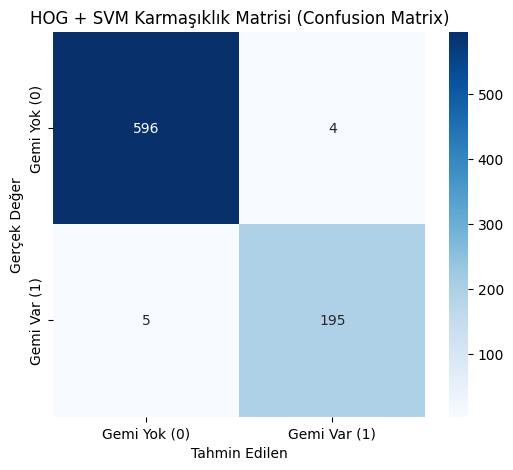

In [4]:
import numpy as np
from skimage.feature import hog
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

print("1. HOG Öznitelikleri Çıkarılıyor...")

# HOG Öznitelik Vektörlerini Oluşturma
hog_features = []
for img in data:
    # Görüntüyü Gri Seviyeye Çevir (HOG gri seviyede çalışır)
    gray = np.dot(img[...,:3], [0.2989, 0.5870, 0.1140])

    # HOG Özniteliklerini Hesapla
    feat = hog(gray, orientations=9, pixels_per_cell=(8, 8),
               cells_per_block=(2, 2), visualize=False)
    hog_features.append(feat)

X = np.array(hog_features)
y = labels

print(f"Öznitelik Vektör Boyutu: {X.shape}")

# 2. Veri Setini Train ve Test Olarak Ayırma (%80 Eğitim, %20 Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Eğitim Verisi: {X_train.shape[0]} | Test Verisi: {X_test.shape[0]}")

# 3. SVM Modelini Eğitme
print("\n2. SVM Modeli Eğitiliyor...")
svm_model = SVC(kernel='rbf', C=10.0, random_state=42)
svm_model.fit(X_train, y_train)

# 4. Test Seti Üzerinde Tahmin Yapma
y_pred = svm_model.predict(X_test)

# 5. Sonuçları Raporlama
acc = accuracy_score(y_test, y_pred)
print(f"\n==========================================")
print(f" Klasik Yöntem (HOG + SVM) Doğruluk Oranı: %{acc*100:.2f}")
print(f"==========================================\n")

print("Detaylı Sınıflandırma Raporu:")
print(classification_report(y_test, y_pred, target_names=['Gemi Yok (0)', 'Gemi Var (1)']))

# Confusion Matrix Görselleştirme
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Gemi Yok (0)', 'Gemi Var (1)'],
            yticklabels=['Gemi Yok (0)', 'Gemi Var (1)'])
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek Değer')
plt.title('HOG + SVM Karmaşıklık Matrisi (Confusion Matrix)')
plt.show()

In [6]:
import os

# Kaydetmek istediğiniz klasör yolunu belirtin
os.makedirs('odev1/data', exist_ok=True)
os.makedirs('odev1/notebooks', exist_ok=True)
os.makedirs('odev1/src', exist_ok=True)

# Klasörler oluşturulduktan sonra dosyanızı güvenle kaydedebilirsiniz
# Örnek: df.to_csv('odev1/data/dataset.csv')